# Deep Hedging : reproduction et mise à l'épreuve sur données financières réelles

**Projet de Deep Learning — M2 ISF**

**Référence :** Brugière, P. & Turinici, G. (2025), *Model-Free Deep Hedging with Transaction Costs and Light Data Requirements*.

## Objectif du projet

Nous étudions la couverture dynamique d'un call européen à l'aide d'un réseau de neurones.

Dans le modèle de Black-Scholes, une stratégie de couverture continue et autofinancée permet de répliquer parfaitement le payoff d'une option, sous les hypothèses du modèle.

En pratique, les transactions sont discrètes et engendrent des coûts. La réplication parfaite n'est alors plus garantie.

L'article de Brugière et Turinici propose d'apprendre une stratégie de couverture à partir d'un nombre limité de trajectoires de prix, en minimisant la dispersion du coût final de couverture.

Notre projet poursuit trois objectifs :

1. **Reproduction :** implémenter l'approche de deep hedging présentée dans l'article et la comparer au delta hedging classique.
2. **Validation empirique :** appliquer les stratégies obtenues à des trajectoires financières historiques, puis évaluer leurs performances hors échantillon.
3. **Analyse de robustesse :** étudier l'effet des coûts de transaction, du choix des données d'entraînement et des caractéristiques du réseau.

Nous chercherons notamment à déterminer si le deep hedging apporte une amélioration mesurable par rapport aux méthodes classiques dans un environnement de trading plus réaliste.

## Méthodologie

Nous commencerons par simuler le prix d'un sous-jacent selon un mouvement brownien géométrique, afin de reproduire le cadre de l'article.

Nous implémenterons ensuite les stratégies de Black-Scholes, de Leland et le modèle de deep hedging en PyTorch.

Enfin, nous évaluerons les stratégies sur des données financières historiques avec différents scénarios de coûts de transaction.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch 

from scipy.stats import norm

# --------------------------------------------------
# Reproductibilité
# --------------------------------------------------

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

# --------------------------------------------------
# Paramètres du mouvement brownien géométrique
# --------------------------------------------------

S0 = 1.0          # Prix initial du sous-jacent
mu = 0.05         # Rendement instantané annuel sous P
sigma = 0.20      # Volatilité annuelle
r = 0.0           # Taux sans risque (cas des tableaux du papier)
T = 0.25          # Maturité : 3 mois en années

N_STEPS = 30      # Nombre d'intervalles de temps
N_TRAIN = 256     # Nombre de trajectoires d'entraînement
N_TEST = 256      # Nombre de trajectoires de test

K = S0            # Call at-the-money initialement
dt = T / N_STEPS  # Durée d'un pas de temps

print(f"Pas de temps : {dt:.6f} année")
print(f"Trajectoires d'entraînement : {N_TRAIN}")
print(f"Trajectoires de test : {N_TEST}")
print(f"Strike : {K}")


Pas de temps : 0.008333 année
Trajectoires d'entraînement : 256
Trajectoires de test : 256
Strike : 1.0


In [ ]:

def simulate_gbm(
    n_paths,
    n_steps,
    S0,
    mu,
    sigma,
    T,
    seed
):
    """
    Simule des trajectoires de mouvement brownien géométrique.

    Returns
    -------
    paths : np.ndarray, shape (n_paths, n_steps + 1)
        Chaque ligne est une trajectoire complète de prix.
    """

    rng = np.random.default_rng(seed)
    dt = T / n_steps

    # Incréments browniens standardisés indépendants
    Z = rng.standard_normal(size=(n_paths, n_steps))

    # Log-rendements sur chaque intervalle
    log_returns = (
        (mu - 0.5 * sigma**2) * dt
        + sigma * np.sqrt(dt) * Z
    )

    # On ajoute la valeur initiale : log(S0/S0) = 0
    log_paths = np.concatenate(
        [np.zeros((n_paths, 1)),
         np.cumsum(log_returns, axis=1)],
        axis=1
    )

    paths = S0 * np.exp(log_paths)

    return paths


# Deux datasets indépendants
train_paths = simulate_gbm(
    N_TRAIN, N_STEPS, S0, mu, sigma, T, seed=42
)

test_paths = simulate_gbm(
    N_TEST, N_STEPS, S0, mu, sigma, T, seed=2026
)

print("Dimensions train :", train_paths.shape)
print("Dimensions test  :", test_paths.shape)

# Vérifications élémentaires
assert train_paths.shape == (256, 31)
assert np.all(train_paths > 0)
assert np.allclose(train_paths[:, 0], S0)


Dimensions train : (256, 31)
Dimensions test  : (256, 31)


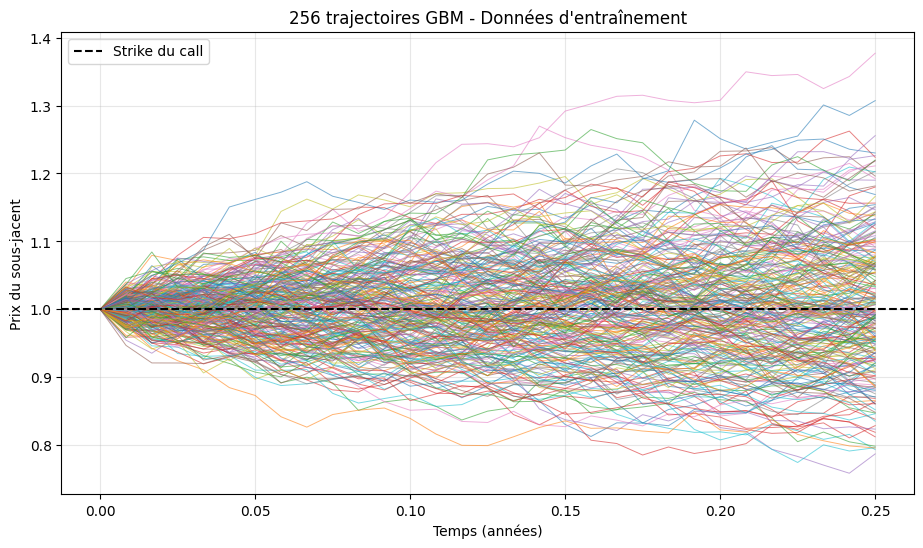

In [9]:

# Dates exprimées en années
times = np.linspace(0, T, N_STEPS + 1)

plt.figure(figsize=(11, 6))

# Affichage des trajectoires d'entraînement
for path in train_paths:
    plt.plot(times, path, alpha=0.58, linewidth=0.7)

plt.axhline(
    K,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Strike du call"
)

plt.xlabel("Temps (années)")
plt.ylabel("Prix du sous-jacent")
plt.title("256 trajectoires GBM - Données d'entraînement")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Delta initial : 0.5199
Delta à la dernière date : 0.6843


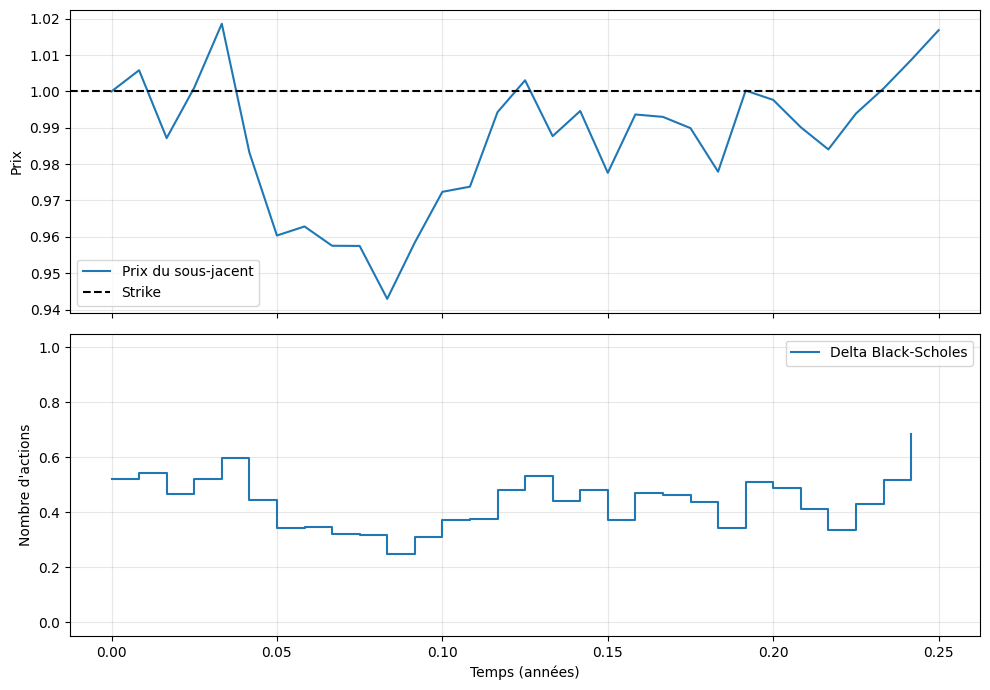

In [10]:

def bs_call_delta(S, K, tau, r, sigma):
    """
    Delta Black-Scholes d'un call européen.

    Parameters
    ----------
    S : float ou np.ndarray
        Prix actuel du sous-jacent.
    K : float
        Strike du call.
    tau : float
        Temps restant jusqu'à maturité, en années.
    r : float
        Taux sans risque.
    sigma : float
        Volatilité annuelle.

    Returns
    -------
    Delta du call.
    """

    S = np.asarray(S, dtype=float)
    tau = np.asarray(tau, dtype=float)

    # Évite une division par zéro à maturité
    tau_safe = np.maximum(tau, 1e-12)

    d1 = (
        np.log(S / K)
        + (r + 0.5 * sigma**2) * tau_safe
    ) / (sigma * np.sqrt(tau_safe))

    delta = norm.cdf(d1)

    # À maturité, le delta devient celui du payoff
    delta = np.where(
        tau <= 0,
        np.where(S > K, 1.0,
                 np.where(S < K, 0.0, 0.5)),
        delta
    )

    return delta


# Exemple : première trajectoire d'entraînement
example_path = train_paths[0]

# Calcul des positions aux 30 dates de couverture
bs_deltas = np.array([
    bs_call_delta(
        S=example_path[i],
        K=K,
        tau=T - times[i],
        r=r,
        sigma=sigma
    )
    for i in range(N_STEPS)
])

print("Delta initial :", round(float(bs_deltas[0]), 4))
print("Delta à la dernière date :", round(float(bs_deltas[-1]), 4))

# Visualisation
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(times, example_path, label="Prix du sous-jacent")
axes[0].axhline(K, color="black", linestyle="--", label="Strike")
axes[0].set_ylabel("Prix")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].step(
    times[:-1],
    bs_deltas,
    where="post",
    label="Delta Black-Scholes"
)
axes[1].set_xlabel("Temps (années)")
axes[1].set_ylabel("Nombre d'actions")
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Première stratégie de référence : delta hedging de Black-Scholes

Pour chaque trajectoire de prix simulée, nous calculons le delta d'un call européen à l'aide de la formule analytique de Black-Scholes.

Le delta représente le nombre d'actions à détenir pour couvrir localement une position vendeuse sur le call.

Dans le modèle de Black-Scholes, la réplication parfaite nécessite un ajustement continu de la stratégie.

Dans notre expérience, les positions ne sont ajustées qu'à 30 dates prédéfinies sur une période de trois mois. La stratégie ne peut donc plus garantir une réplication parfaite, même en l'absence de coûts de transaction.

Cette stratégie constitue notre première **baseline**, à laquelle nous comparerons les positions produites par le réseau de neurones.

Le réseau ne sera pas entraîné à reproduire les deltas Black-Scholes. Il apprendra directement une stratégie de couverture en minimisant l'écart-type du coût terminal actualisé de la couverture.

In [11]:

def hedging_cost(paths, hedges, alpha):
    """
    Calcule Z_T, le coût actualisé de couverture.

    Parameters
    ----------
    paths : torch.Tensor, shape (batch, n_steps + 1)
        Trajectoires du sous-jacent.

    hedges : torch.Tensor, shape (batch, n_steps)
        Positions en actions aux dates 0,...,n_steps-1.

    alpha : float
        Coût de transaction proportionnel.
        Exemple : 0.02 représente 2 %.

    Returns
    -------
    torch.Tensor, shape (batch,)
        Coût actualisé, normalisé par le prix initial.

    Conventions reprises de l'article :
    - Pas de frais sur la position initiale.
    - Call à livraison physique.
    - Frais sur les transactions intermédiaires.
    - Traitement particulier des positions à maturité.
    """

    n = hedges.shape[1]

    # Prix exprimés relativement au prix initial
    prices = paths / paths[:, :1]

    gamma = torch.exp(
        torch.tensor(
            -r * dt,
            dtype=paths.dtype,
            device=paths.device
        )
    )

    # 1. Coût de la position initiale
    cost = hedges[:, 0]

    # 2. Transactions intermédiaires
    changes = hedges[:, 1:] - hedges[:, :-1]

    discount = gamma ** torch.arange(
        1, n,
        device=paths.device,
        dtype=paths.dtype
    )

    intermediate_costs = (
        (changes + alpha * torch.abs(changes))
        * prices[:, 1:n]
        * discount.unsqueeze(0)
    )

    cost = cost + intermediate_costs.sum(dim=1)

    # 3. Règlement à maturité
    final_price = prices[:, -1]
    final_hedge = hedges[:, -1]

    # Call hors de la monnaie :
    # on liquide intégralement la position en actions.
    cost_otm = (
        - torch.relu(final_hedge)
        * (1 - alpha) * final_price
        + torch.relu(-final_hedge)
        * (1 + alpha) * final_price
    )

    # Call dans la monnaie :
    # on reçoit K et on livre une action.
    # On achète ou vend seulement les actions manquantes
    # ou excédentaires.
    cost_itm = (
        - K
        + torch.relu(1 - final_hedge)
        * (1 + alpha) * final_price
        - torch.relu(final_hedge - 1)
        * (1 - alpha) * final_price
    )

    terminal_cost = torch.where(
        final_price < K,
        cost_otm,
        cost_itm
    )

    cost = cost + (gamma ** n) * terminal_cost

    return cost


In [12]:

def bs_hedging_positions(paths):
    """
    Calcule les positions Black-Scholes sur un batch.

    paths : np.ndarray, shape (n_paths, n_steps + 1)
    """

    hedge_times = np.arange(N_STEPS) * dt
    tau = T - hedge_times

    return bs_call_delta(
        paths[:, :-1],
        K,
        tau[None, :],
        r,
        sigma
    )


# Conversion NumPy -> PyTorch
train_tensor = torch.tensor(train_paths, dtype=torch.float32)
test_tensor = torch.tensor(test_paths, dtype=torch.float32)

# Delta Black-Scholes sur toutes les trajectoires
bs_train = torch.tensor(
    bs_hedging_positions(train_paths),
    dtype=torch.float32
)

bs_test = torch.tensor(
    bs_hedging_positions(test_paths),
    dtype=torch.float32
)

# Tests sans frais puis avec 2 % de frais
for alpha in [0.0, 0.02]:

    costs = hedging_cost(test_tensor, bs_test, alpha)

    print(f"\nFrais de transaction : {alpha:.1%}")
    print(f"Coût moyen : {costs.mean().item():.4%}")
    print(
        "Écart-type : "
        f"{costs.std(unbiased=False).item():.4%}"
    )



Frais de transaction : 0.0%
Coût moyen : 4.0969%
Écart-type : 0.6325%

Frais de transaction : 2.0%
Coût moyen : 7.6691%
Écart-type : 1.6671%


In [13]:

import torch.nn as nn

class DeltaNN(nn.Module):
    """
    Réseau dense de couverture inspiré de l'article.

    Entrées :
        1. S_t / K
        2. Temps restant jusqu'à maturité
        3. Position précédente H_(t-1)

    Sortie :
        Nouvelle position H_t
    """

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(3, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


model = DeltaNN()

print(model)
print(
    "Nombre de paramètres :",
    sum(p.numel() for p in model.parameters())
)


DeltaNN(
  (network): Sequential(
    (0): Linear(in_features=3, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Nombre de paramètres : 2369


In [14]:

def neural_hedging_positions(model, paths):
    """
    Applique le même réseau à toutes les dates.

    Parameters
    ----------
    model : DeltaNN
        Réseau de couverture.

    paths : torch.Tensor
        Prix, shape (batch, n_steps + 1).

    Returns
    -------
    torch.Tensor
        Positions, shape (batch, n_steps).
    """

    batch_size = paths.shape[0]
    n_steps = paths.shape[1] - 1

    # Aucune action détenue avant la première décision
    previous_hedge = torch.zeros(
        batch_size,
        dtype=paths.dtype,
        device=paths.device
    )

    positions = []

    for i in range(n_steps):

        # Informations disponibles à la date t_i
        current_price = paths[:, i] / K

        remaining_time = torch.full_like(
            current_price,
            T - i * dt
        )

        # Les trois variables du réseau
        features = torch.stack(
            [
                current_price,
                remaining_time,
                previous_hedge
            ],
            dim=1
        )

        # Nouvelle position décidée par le réseau
        current_hedge = model(features)

        positions.append(current_hedge)

        # La position devient l'entrée de la date suivante
        previous_hedge = current_hedge

    return torch.stack(positions, dim=1)


# Test avant entraînement
with torch.no_grad():
    initial_positions = neural_hedging_positions(
        model,
        test_tensor
    )

print("Dimensions :", initial_positions.shape)
print("Premières positions :")
print(initial_positions[0, :5])


Dimensions : torch.Size([256, 30])
Premières positions :
tensor([-0.0137, -0.0147, -0.0143, -0.0161, -0.0145])


In [15]:

# --------------------------------------------------
# Configuration de l'entraînement
# --------------------------------------------------

torch.manual_seed(SEED)

model = DeltaNN()

ALPHA = 0.02
N_EPOCHS = 500
BATCH_SIZE = 64

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

train_losses = []
test_losses = []

# --------------------------------------------------
# Boucle d'entraînement
# --------------------------------------------------

for epoch in range(N_EPOCHS):

    model.train()

    # On mélange les trajectoires d'entraînement
    permutation = torch.randperm(len(train_tensor))

    for indices in permutation.split(BATCH_SIZE):

        batch = train_tensor[indices]

        # 1. Le réseau choisit ses positions
        positions = neural_hedging_positions(
            model,
            batch
        )

        # 2. Calcul des coûts finaux de couverture
        costs = hedging_cost(
            batch,
            positions,
            ALPHA
        )

        # 3. Fonction de perte : dispersion des coûts
        loss = costs.std(unbiased=False)

        # 4. Backpropagation et mise à jour des poids
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # --------------------------------------------------
    # Suivi des performances en fin d'epoch
    # --------------------------------------------------

    model.eval()

    with torch.no_grad():

        train_positions = neural_hedging_positions(
            model, train_tensor
        )

        train_costs = hedging_cost(
            train_tensor, train_positions, ALPHA
        )

        test_positions = neural_hedging_positions(
            model, test_tensor
        )

        test_costs = hedging_cost(
            test_tensor, test_positions, ALPHA
        )

        train_std = train_costs.std(
            unbiased=False
        ).item()

        test_std = test_costs.std(
            unbiased=False
        ).item()

    train_losses.append(train_std)
    test_losses.append(test_std)

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch+1:3d}/{N_EPOCHS} | "
            f"Train std : {train_std:.4%} | "
            f"Test std : {test_std:.4%}"
        )

print("\nEntraînement terminé.")


Epoch  50/500 | Train std : 2.3327% | Test std : 2.2623%
Epoch 100/500 | Train std : 1.1437% | Test std : 1.2420%
Epoch 150/500 | Train std : 1.0136% | Test std : 1.0393%
Epoch 200/500 | Train std : 0.9496% | Test std : 0.9913%
Epoch 250/500 | Train std : 0.9152% | Test std : 0.9606%
Epoch 300/500 | Train std : 0.8991% | Test std : 0.9846%
Epoch 350/500 | Train std : 0.8773% | Test std : 0.9359%
Epoch 400/500 | Train std : 0.8511% | Test std : 0.9229%
Epoch 450/500 | Train std : 0.8477% | Test std : 0.9191%
Epoch 500/500 | Train std : 0.8564% | Test std : 0.9293%

Entraînement terminé.


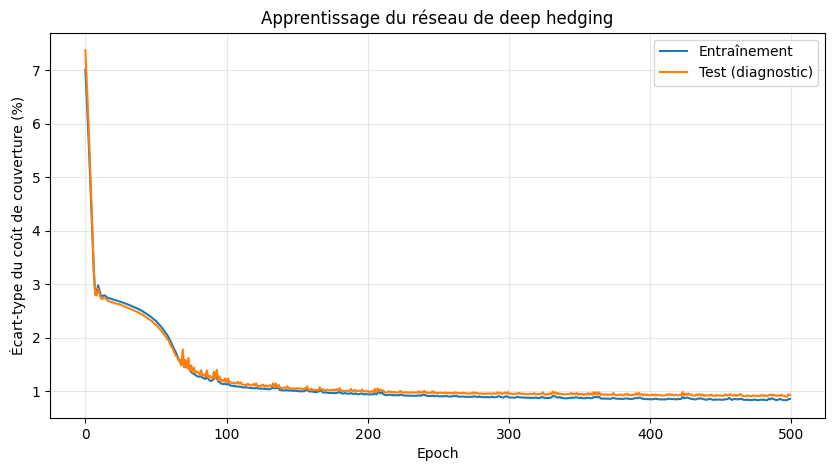

In [16]:

plt.figure(figsize=(10, 5))

plt.plot(
    np.array(train_losses) * 100,
    label="Entraînement"
)

plt.plot(
    np.array(test_losses) * 100,
    label="Test (diagnostic)"
)

plt.xlabel("Epoch")
plt.ylabel("Écart-type du coût de couverture (%)")
plt.title("Apprentissage du réseau de deep hedging")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [17]:

# Coûts de Black-Scholes
costs_bs = hedging_cost(
    test_tensor,
    bs_test,
    ALPHA
)

# Coûts du réseau entraîné
model.eval()

with torch.no_grad():
    nn_positions = neural_hedging_positions(
        model,
        test_tensor
    )

    costs_nn = hedging_cost(
        test_tensor,
        nn_positions,
        ALPHA
    )


def summarize_costs(costs, name):
    return {
        "Méthode": name,
        "Coût moyen (%)": 100 * costs.mean().item(),
        "Écart-type (%)": 100 * costs.std(
            unbiased=False
        ).item(),
        "Coût minimum (%)": 100 * costs.min().item(),
        "Coût maximum (%)": 100 * costs.max().item()
    }


results = pd.DataFrame([
    summarize_costs(costs_bs, "Black-Scholes"),
    summarize_costs(costs_nn, "Deep Hedging")
])

display(results.round(3))


,Méthode,Coût moyen (%),Écart-type (%),Coût minimum (%),Coût maximum (%)
0,Black-Scholes,7.669,1.667,4.712,14.018
1,Deep Hedging,6.811,0.929,3.600,10.322


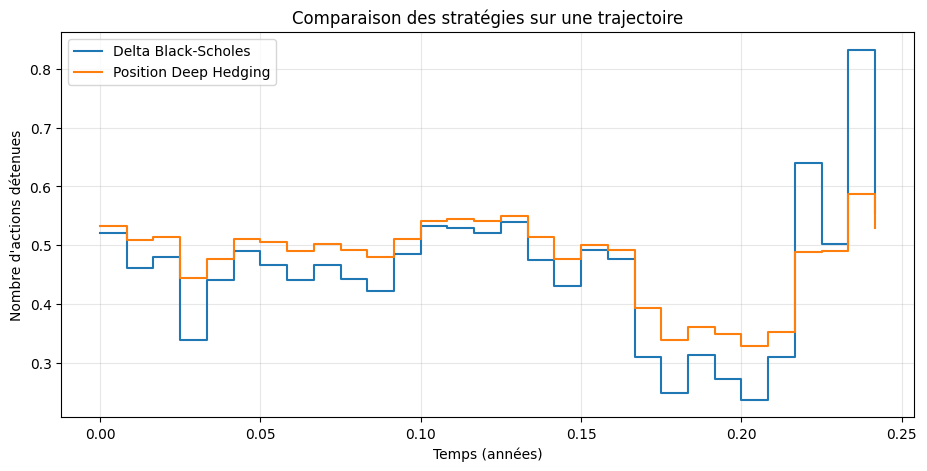

In [18]:

path_id = 0

plt.figure(figsize=(11, 5))

plt.step(
    times[:-1],
    bs_test[path_id].numpy(),
    where="post",
    label="Delta Black-Scholes"
)

plt.step(
    times[:-1],
    nn_positions[path_id].detach().numpy(),
    where="post",
    label="Position Deep Hedging"
)

plt.xlabel("Temps (années)")
plt.ylabel("Nombre d'actions détenues")
plt.title("Comparaison des stratégies sur une trajectoire")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [19]:

def trading_statistics(positions, alpha, threshold=1e-4):
    """
    Mesure l'activité de trading d'une stratégie.

    threshold : variation minimale de position considérée
                comme une transaction.

    Les transactions initiales et la liquidation finale
    sont exclues de ce premier indicateur.
    """

    changes = torch.diff(positions, dim=1)

    turnover = torch.abs(changes).sum(dim=1)

    n_trades = (
        torch.abs(changes) > threshold
    ).sum(dim=1)

    return {
        "Transactions moyennes": n_trades.float().mean().item(),
        "Volume moyen échangé": turnover.mean().item(),
    }


stats_bs = trading_statistics(bs_test, ALPHA)
stats_nn = trading_statistics(nn_positions, ALPHA)

trading_results = pd.DataFrame([
    {"Méthode": "Black-Scholes", **stats_bs},
    {"Méthode": "Deep Hedging", **stats_nn}
])

display(trading_results.round(3))


,Méthode,Transactions moyennes,Volume moyen échangé
0,Black-Scholes,27.934,1.712
1,Deep Hedging,28.941,1.173
